# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Khanum Nawra Attar
- **Email:** khanumattr@gmail.com
- **ID Dicoding:** khanumattr

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- PERTANYAAN 1:
**Selama Januari–Desember 2017, bagaimana perubahan bulanan nilai penjualan produk (GMV, tidak termasuk ongkos kirim) dan jumlah pesanan yang telah berstatus delivered, serta bulan mana yang harus diprioritaskan untuk perencanaan stok dan promosi?**
- PERTANYAAN 2:
**Selama Januari–Desember 2017, apa lima kategori produk dengan kontribusi GMV terbesar pada pesanan delivered, berapa persentase kontribusinya, dan bagaimana skor ulasan rata-ratanya untuk menentukan prioritas promosi serta perbaikan pengalaman pelanggan?**

## Import Semua Packages/Library yang Digunakan

In [15]:
from pathlib import Path
from zipfile import ZipFile
import shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

DATA_DIR = Path("data/raw")
OUTPUT_DIR = Path("data/processed")
FIG_DIR = Path("visualizations")
for folder in [DATA_DIR, OUTPUT_DIR, FIG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

## Data Wrangling

### Gathering Data

In [16]:
orders_df = pd.read_csv(
    DATA_DIR / "orders_dataset.csv"
)

items_df = pd.read_csv(
    DATA_DIR / "order_items_dataset.csv"
)

products_df = pd.read_csv(
    DATA_DIR / "products_dataset.csv"
)

translations_df = pd.read_csv(
    DATA_DIR / "product_category_name_translation.csv"
)

reviews_df = pd.read_csv(
    DATA_DIR / "order_reviews_dataset.csv"
)

for name, df in {
    "orders": orders_df,
    "items": items_df,
    "products": products_df,
    "translations": translations_df,
    "reviews": reviews_df
}.items():
    print(name, df.shape)

display(orders_df.head())
display(items_df.head())

orders (99441, 8)
items (112650, 7)
products (32951, 9)
translations (71, 2)
reviews (99224, 7)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


Terdapat lima tabel yang relevan: orders, order_items, products product_category_name_translation, products dan order_reviews untuk menjawab pertanyaan bisnis.

### Assessing Data

In [17]:
datasets = {
    "orders": orders_df,
    "items": items_df,
    "products": products_df,
    "reviews": reviews_df
}

for name, df in datasets.items():
    print(f"\n=== {name.upper()} ===")
    print("Missing Values:")
    print(df.isna().sum())
    print("Duplikasi baris:", df.duplicated().sum())

print(
    "Kategori kosong:",
    products_df["product_category_name"].isna().sum()
)

print(
    "Order ID berulang pada review:",
    reviews_df["order_id"].duplicated().sum()
)

print(
    "Harga tidak positif:",
    (items_df["price"] <= 0).sum()
)


=== ORDERS ===
Missing Values:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64
Duplikasi baris: 0

=== ITEMS ===
Missing Values:
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64
Duplikasi baris: 0

=== PRODUCTS ===
Missing Values:
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64
Duplikasi baris: 0

=== REVIEWS ===
Missi

**Insight:**
- Missing Values: Ditemukan nilai kosong pada dataset orders, products, dan reviews. Sebanyak 610 produk tidak memiliki informasi kategori, sementara 87.656 ulasan tidak memiliki judul dan 58.247 ulasan tidak memiliki komentar.
- Duplicate Data: Tidak ditemukan duplikasi baris pada keempat dataset. Namun, terdapat 551 pengulangan order_id pada dataset reviews yang perlu diperhatikan saat penggabungan data.
- Invalid Values: Tidak ditemukan harga produk bernilai nol atau negatif, sehingga seluruh nilai harga lolos pemeriksaan tersebut.

**Steps to Take:**
1.   Menyaring pesanan dengan status delivered dan periode transaksi tahun 2017.
2. Mengisi kategori produk yang kosong dengan Unknown.
3. Mengelompokkan skor ulasan berdasarkan order_id menggunakan nilai rata-rata untuk menghindari penggandaan data saat penggabungan.
4. Mempertahankan nilai kosong pada judul dan komentar ulasan karena analisis hanya menggunakan review_score.
5. Memvalidasi harga produk dan ongkos kirim sebelum menggabungkan seluruh dataset.



### Cleaning Data

#### Fixing ... problem

In [18]:
orders_df["order_purchase_timestamp"] = pd.to_datetime(
    orders_df["order_purchase_timestamp"],
    errors="coerce"
)

orders_2017 = orders_df[
    (orders_df["order_status"] == "delivered") &
    (
        orders_df["order_purchase_timestamp"].between(
            "2017-01-01", "2017-12-31 23:59:59"
        )
    )
][["order_id", "order_purchase_timestamp"]].copy()

items_clean = items_df[
    (items_df["price"] > 0) &
    (items_df["freight_value"] >= 0)
].copy()

reviews_clean = reviews_df[
    ["order_id", "review_score"]
].copy()

reviews_clean.loc[
    ~reviews_clean["review_score"].between(1, 5),
    "review_score"
] = np.nan

reviews_per_order = (
    reviews_clean.groupby("order_id", as_index=False)
    .agg(review_score=("review_score", "mean"))
)

analysis_df = (
    items_clean
    .merge(
        orders_2017,
        on="order_id",
        how="inner",
        validate="many_to_one"
    )
    .merge(
        products_df[["product_id", "product_category_name"]],
        on="product_id",
        how="left",
        validate="many_to_one"
    )
    .merge(
        translations_df,
        on="product_category_name",
        how="left",
        validate="many_to_one"
    )
    .merge(
        reviews_per_order,
        on="order_id",
        how="left",
        validate="many_to_one"
    )
)

analysis_df["category"] = (
    analysis_df["product_category_name_english"]
    .fillna(analysis_df["product_category_name"])
    .fillna("Unknown")
)

analysis_df["month"] = (
    analysis_df["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

analysis_df = analysis_df.rename(
    columns={
        "order_purchase_timestamp": "purchase_datetime"
    }
)

analysis_df = analysis_df[
    [
        "order_id",
        "order_item_id",
        "purchase_datetime",
        "month",
        "category",
        "price",
        "freight_value",
        "review_score"
    ]
]

analysis_df.to_csv(
    OUTPUT_DIR / "main_data.csv",
    index=False
)

print("Jumlah data bersih:", len(analysis_df))
print("Jumlah pesanan:", analysis_df["order_id"].nunique())

Jumlah data bersih: 49556
Jumlah pesanan: 43428


**Insight:**
- Data bersih disimpan untuk digunakan kembali pada EDA dan dashboard Streamlit.

## Exploratory Data Analysis (EDA)

### Explore Pertanyaan Bisnis 1 — Tren Penjualan
Tujuan eksplorasi ini adalah memperoleh total nilai penjualan, jumlah pesanan, dan perubahan penjualan bulanan.

In [19]:
monthly = (
    analysis_df.groupby("month", as_index=False)
    .agg(
        gmv=("price", "sum"),
        orders=("order_id", "nunique"),
        units=("order_item_id", "size")
    )
    .sort_values("month")
)

monthly["gmv_growth_pct"] = (
    monthly["gmv"].pct_change() * 100
)

monthly["order_growth_pct"] = (
    monthly["orders"].pct_change() * 100
)

display(monthly)

,month,gmv,orders,units,gmv_growth_pct,order_growth_pct
0,2017-01,"111,798.36",750,913,NaN,NaN
1,2017-02,"234,223.40",1653,1858,109.51,120.40
2,2017-03,"359,198.85",2546,2897,53.36,54.02
3,2017-04,"340,669.68",2303,2569,-5.16,-9.54
4,2017-05,"489,338.25",3546,4004,43.64,53.97
5,2017-06,"421,923.37",3135,3489,-13.78,-11.59
6,2017-07,"481,604.52",3872,4416,14.15,23.51
7,2017-08,"554,699.70",4193,4797,15.18,8.29
8,2017-09,"607,399.67",4150,4737,9.50,-1.03
9,2017-10,"648,247.65",4478,5214,6.73,7.90


**Insight:**
*Terdapat peningkatan nilai penjualan yang cukup besar pada November, kemudian nilai penjualan menurun pada Desember.*

### Explore Pertanyaan Bisnis 2 — Kategori dan Ulasan
Tujuan eksplorasi ini adalah memperoleh total nilai penjualan, jumlah pesanan, dan perubahan penjualan bulanan.

In [20]:
category_sales = (
    analysis_df.groupby("category", as_index=False)
    .agg(
        gmv=("price", "sum"),
        units=("order_item_id", "size"),
        orders=("order_id", "nunique")
    )
)

category_reviews = (
    analysis_df[
        ["order_id", "category", "review_score"]
    ]
    .drop_duplicates(["order_id", "category"])
    .groupby("category", as_index=False)
    .agg(
        avg_review=("review_score", "mean"),
        reviewed_orders=("review_score", "count")
    )
)

category_summary = (
    category_sales
    .merge(category_reviews, on="category", how="left")
    .sort_values("gmv", ascending=False)
)

category_summary["gmv_share_pct"] = (
    category_summary["gmv"] /
    category_summary["gmv"].sum() * 100
)

display(category_summary.head(10))

,category,gmv,units,orders,avg_review,reviewed_orders,gmv_share_pct
8,bed_bath_table,"490,596.92",5135,4423,4.01,4373,8.23
72,watches_gifts,"475,610.71",2227,2073,4.19,2058,7.98
44,health_beauty,"473,833.00",3581,3305,4.24,3287,7.95
67,sports_leisure,"435,674.14",3978,3540,4.30,3517,7.31
16,computers_accessories,"391,786.29",3010,2546,4.16,2531,6.57
21,cool_stuff,"381,414.30",2264,2161,4.28,2144,6.40
40,furniture_decor,"324,587.60",4044,3111,4.04,3082,5.44
71,toys,"299,056.71",2552,2404,4.26,2384,5.02
43,garden_tools,"256,949.20",2414,1934,4.19,1919,4.31
6,auto,"234,550.09",1552,1383,4.14,1372,3.93


**Insight:**
*Kelima kategori memberikan sekitar 38,03% dari total nilai penjualan. Kategori bed_bath_table memiliki GMV tertinggi, tetapi rata-rata ulasannya paling rendah di antara lima kategori teratas.*

## Visualization & Explanatory Analysis

### Pertanyaan 1:

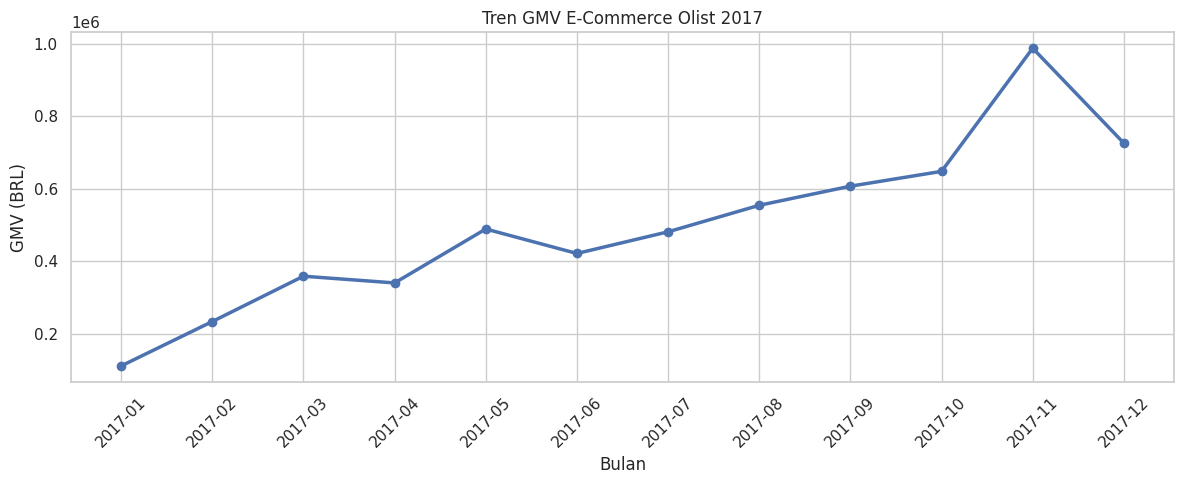

In [21]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    monthly["month"],
    monthly["gmv"],
    marker="o",
    linewidth=2.5
)

ax.set_title("Tren GMV E-Commerce Olist 2017")
ax.set_xlabel("Bulan")
ax.set_ylabel("GMV (BRL)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Insight:**
1. Nilai penjualan (GMV) menunjukkan tren peningkatan sepanjang tahun 2017, meskipun terjadi beberapa penurunan pada April, Juni, dan Desember.
2. GMV tertinggi terjadi pada November 2017, meningkat sebesar 52,37% dibandingkan Oktober.
3. GMV terendah terjadi pada Januari 2017, yaitu sekitar R$111.798, kemudian mengalami peningkatan pada bulan-bulan berikutnya.
4. Penurunan GMV pada Desember setelah mencapai puncak pada November menunjukkan adanya fluktuasi penjualan yang perlu diperhatikan dalam perencanaan stok dan strategi promosi.

### Pertanyaan 2:

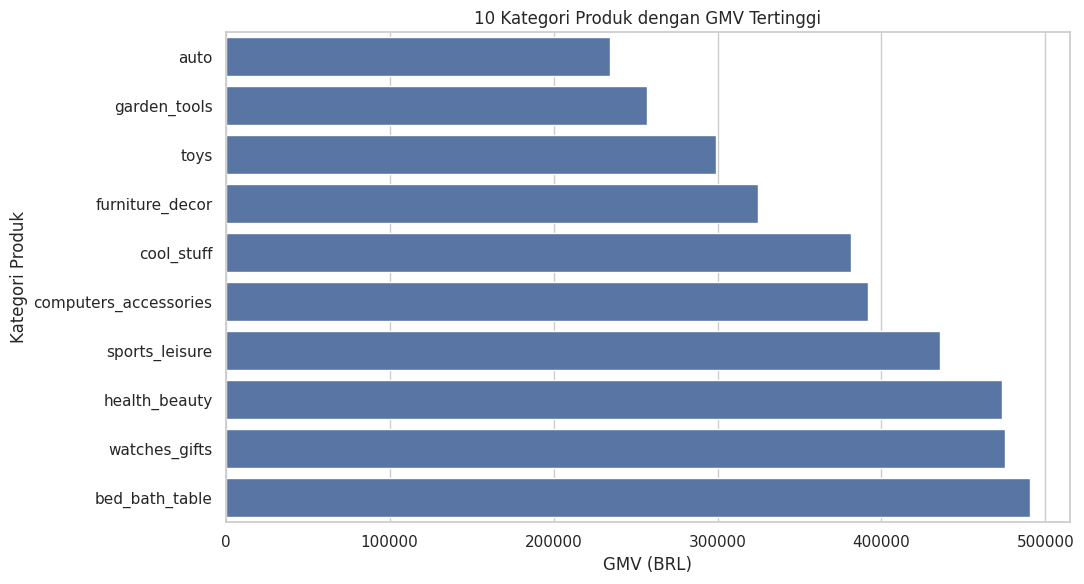

In [22]:
top10 = (
    category_summary.head(10)
    .sort_values("gmv")
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top10,
    x="gmv",
    y="category"
)

plt.title("10 Kategori Produk dengan GMV Tertinggi")
plt.xlabel("GMV (BRL)")
plt.ylabel("Kategori Produk")
plt.tight_layout()
plt.show()


**Insight:**
**10 Kategori Produk dengan GMV Tertinggi**
1. Kategori bed_bath_table memiliki kontribusi GMV tertinggi, yaitu sekitar 8,23% dari total penjualan.
2. Kategori watches_gifts dan health_beauty menempati posisi kedua dan ketiga dengan GMV masing-masing sekitar R$475.611 dan R$473.833.
3. Lima kategori dengan GMV tertinggi menyumbang sekitar 38,03% dari total penjualan, menunjukkan bahwa kategori tersebut memiliki peranan penting terhadap pendapatan penjualan produk.
4. Kategori dengan kontribusi GMV terbesar dapat menjadi prioritas dalam perencanaan persediaan dan strategi promosi.

Untuk memperkuat jawaban pertanyaan kedua, visualisasi dibawah menampilkan perbandingan skor ulasan lima kategori dengan GMV tertinggi

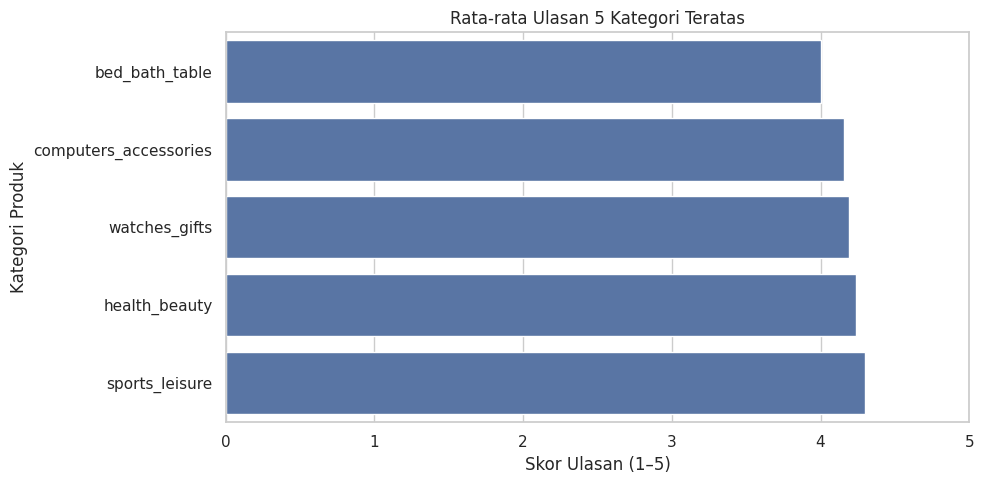

In [23]:
top5 = (
    category_summary.head(5)
    .sort_values("avg_review")
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=top5,
    x="avg_review",
    y="category"
)

plt.xlim(0, 5)
plt.title("Rata-rata Ulasan 5 Kategori Teratas")
plt.xlabel("Skor Ulasan (1–5)")
plt.ylabel("Kategori Produk")
plt.tight_layout()
plt.show()

**Insight:**
**Rata-rata Ulasan 5 Kategori Teratas**
1. Kategori sports_leisure memperoleh rata-rata skor ulasan tertinggi, yaitu sekitar 4,30 dari skala 5, yang menunjukkan penilaian pelanggan relatif positif.
2. Kategori bed_bath_table memiliki rata-rata skor ulasan terendah di antara lima kategori teratas, yaitu sekitar 4,01, meskipun memberikan kontribusi GMV terbesar.
3. Kategori health_beauty, watches_gifts, dan computers_accessories memiliki rata-rata skor ulasan berkisar antara 4,16 hingga 4,24, menunjukkan tingkat penilaian yang relatif baik.
4. Perbedaan skor ulasan menunjukkan bahwa besarnya nilai penjualan tidak selalu sejalan dengan tingginya penilaian pelanggan. Oleh karena itu, kategori bed_bath_table dapat diprioritaskan untuk evaluasi pengalaman pelanggan.

## Conclusion & Recommendation


## Conclusion

### 1. Kesimpulan Pertanyaan Bisnis 1

**Pertanyaan Bisnis:**

Selama Januari–Desember 2017, bagaimana perubahan bulanan nilai penjualan produk (GMV, tidak termasuk ongkos kirim) dan jumlah pesanan yang telah berstatus delivered, serta bulan mana yang perlu diprioritaskan untuk perencanaan stok dan promosi?

**Kesimpulan:**

Berdasarkan hasil analisis data e-commerce Olist sepanjang tahun 2017, diperoleh beberapa kesimpulan:

1. Total nilai penjualan produk mencapai **5.962.902,01 BRL**, yang berasal dari **43.428 pesanan** berstatus delivered.
2. Nilai penjualan tertinggi terjadi pada **November 2017**, yaitu sebesar **987.765,37 BRL**, meningkat sekitar **52,37%** dibandingkan Oktober.
3. Peningkatan tersebut disertai pertumbuhan jumlah pesanan dari **4.478 menjadi 7.289 pesanan**.
4. November merupakan periode dengan aktivitas penjualan tertinggi selama tahun pengamatan, sehingga dapat menjadi prioritas dalam perencanaan stok dan strategi promosi.

### 2. Kesimpulan Pertanyaan Bisnis 2

**Pertanyaan Bisnis:**

Selama Januari–Desember 2017, apa lima kategori produk dengan kontribusi GMV terbesar pada pesanan delivered, berapa persentase kontribusinya, dan bagaimana skor ulasan rata-ratanya untuk menentukan prioritas promosi serta perbaikan pengalaman pelanggan?

**Kesimpulan:**

Berdasarkan hasil analisis kategori produk dan ulasan pelanggan, diperoleh beberapa kesimpulan:

1. Lima kategori dengan kontribusi GMV terbesar adalah **bed_bath_table, watches_gifts, health_beauty, sports_leisure, dan computers_accessories**, dengan kontribusi gabungan sekitar **38,03%** terhadap total GMV.
2. Kategori **bed_bath_table** memiliki kontribusi GMV tertinggi, yaitu **8,23%** dari total penjualan.
3. Kategori **sports_leisure** memperoleh rata-rata skor ulasan tertinggi di antara lima kategori tersebut, yaitu sekitar **4,30 dari 5**.
4. Meskipun memiliki kontribusi penjualan terbesar, kategori **bed_bath_table** memperoleh skor ulasan terendah di antara lima kategori teratas, yaitu sekitar **4,01 dari 5**.
5. Kategori **bed_bath_table** perlu diprioritaskan untuk evaluasi pengalaman pelanggan, sedangkan kategori dengan kontribusi GMV tinggi dapat menjadi fokus strategi promosi.



## Recommendation & Action Items

Berdasarkan hasil analisis data e-commerce sepanjang tahun 2017, terdapat beberapa rekomendasi tindakan yang dapat dilakukan untuk meningkatkan kinerja penjualan dan kualitas pengalaman pelanggan.

### 1. Optimalisasi Persediaan dan Strategi Promosi

**Temuan:** November 2017 mencatat GMV tertinggi sebesar 987.765,37 BRL, dengan peningkatan 52,37% dibandingkan Oktober.

**Action Items:**
- Melakukan evaluasi kebutuhan stok sebelum periode dengan permintaan tinggi, khususnya menjelang November.
- Menyiapkan strategi promosi lebih awal berdasarkan tren penjualan historis.
- Memantau jumlah pesanan dan GMV bulanan untuk mengantisipasi perubahan permintaan.

**Indikator Keberhasilan:** Ketersediaan stok, pertumbuhan GMV, dan jumlah pesanan selama periode promosi.

### 2. Prioritas Pengembangan Kategori Produk Unggulan

**Temuan:** Lima kategori produk teratas menyumbang sekitar 38,03% dari total GMV, dengan kategori bed_bath_table sebagai kontributor terbesar sebesar 8,23%.

**Action Items:**
- Memprioritaskan ketersediaan produk pada kategori dengan kontribusi GMV tertinggi.
- Mengevaluasi efektivitas promosi pada lima kategori unggulan.
- Mengembangkan strategi pemasaran berdasarkan kontribusi penjualan masing-masing kategori.

**Indikator Keberhasilan:** Pertumbuhan GMV per kategori, jumlah pesanan, dan kontribusi kategori terhadap total penjualan.

### 3. Peningkatan Kepuasan Pelanggan

**Temuan:** Kategori bed_bath_table memiliki rata-rata skor ulasan terendah di antara lima kategori teratas, yaitu sekitar 4,01 dari skala 5.

**Action Items:**
- Mengevaluasi ulasan pelanggan untuk mengidentifikasi keluhan yang paling sering muncul.
- Melakukan pemeriksaan kualitas produk, kesesuaian deskripsi, serta proses pengiriman.
- Memantau perubahan skor ulasan secara berkala untuk mengevaluasi hasil perbaikan.

**Indikator Keberhasilan:** Peningkatan rata-rata skor ulasan kategori bed_bath_table dengan target awal minimal 4,20 dari skala 5.

### 4. Peningkatan Kualitas Data Produk

**Temuan:** Ditemukan 610 produk tanpa informasi kategori pada tahap Assessing Data.

**Action Items:**
- Melengkapi informasi kategori produk yang belum tersedia.
- Melakukan validasi data produk sebelum disimpan ke dalam sistem.
- Melaksanakan pemeriksaan kualitas data secara berkala agar hasil analisis lebih akurat.

**Indikator Keberhasilan:** Penurunan jumlah produk tanpa kategori dan peningkatan kelengkapan data produk.

### Rekomendasi Akhir

Prioritas utama yang disarankan adalah **mengoptimalkan kesiapan persediaan menjelang periode penjualan tinggi dan meningkatkan pengalaman pelanggan pada kategori bed_bath_table**. Kedua tindakan tersebut dapat mendukung keberlanjutan penjualan sekaligus menjaga kualitas pelayanan pelanggan.

Rekomendasi ini didasarkan pada pola historis tahun 2017. Efektivitas tindakan perlu dievaluasi menggunakan data periode berikutnya.
